# Mini Project 10 — Running Project Keyword Spotting Embedded

**Anggota Kelompok:**
1. Christama Ezra Yudianto (245150307111009)
2. Abdillah Fatah Suryanto (245150300111008)
3. Ivang Arfandia (245150307111003)
4. Jahzeel Erason Nicodemus (245150300111002)

Notebook ini dibangkitkan dari `mini_project_10.py` (bagian wajib) dan `features/mp10_extension_selection_analysis.py` (FITUR TAMBAHAN) lalu dieksekusi dari root folder mini project.

# Mini Project 10 — Seleksi Fitur dan Pembekuan Representasi untuk MP11
Membaca dataset 39-D + split beku MP9. Semua fit (scaler, MI, RFE, PCA, LDA) dan
pemilihan kandidat dilakukan **hanya pada TRAIN** dengan GroupKFold per acquisition block.
Kebijakan hardware-aware: kandidat *selection* terkecil dalam toleransi F1 0.03.
Status -> `ready_for_mp11`.

In [1]:
# Anggota Kelompok :
# 1. Christama Ezra Yudianto    (245150307111009)
# 2. Abdillah Fatah Suryanto    (245150300111008)
# 3. Ivang Arfandia             (245150307111003)
# 4. Jahzeel Erason Nicodemus   (245150300111002)
from pathlib import Path
import json
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
SEED = 2026
F1_TOLERANCE = 0.03
CORR_THRESHOLD = 0.95

## Helper

In [2]:
def load_json(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)


def save_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)


def mi_score(X, y):
    return mutual_info_classif(X, y, random_state=SEED)


def cv_macro_f1(pipe, X, y, groups):
    n_groups = len(np.unique(groups))
    cv = GroupKFold(n_splits=n_groups)
    scores = cross_val_score(pipe, X, y, groups=groups, cv=cv, scoring='f1_macro')
    return scores.astype(float)


def transform_selected(X, scaler, indices):
    Xs = scaler.transform(X)
    return Xs[:, indices]

## 1. Validasi handoff MP9

In [3]:
status_path = ROOT / 'project_status.json'
status = load_json(status_path)
if status.get('status') not in ('ready_for_mp10', 'ready_for_mp11'):
    raise RuntimeError('MP9 belum siap. Status harus ready_for_mp10.')

data_path = ROOT / 'features/dataset/mp09_features_39d.npz'
if not data_path.exists():
    raise FileNotFoundError(data_path)

D = np.load(data_path, allow_pickle=True)
X = D['X'].astype(np.float64)
y = D['y'].astype(str)
groups = D['groups'].astype(str)
sample_ids = D['sample_ids'].astype(str)
feature_names = D['feature_names'].astype(str)
train_mask = D['train_mask'].astype(bool)
val_mask = D['val_mask'].astype(bool)
test_mask = D['test_mask'].astype(bool)

X_train = X[train_mask]
y_train = y[train_mask]
g_train = groups[train_mask]

if X.shape[1] != 39:
    raise RuntimeError(f'Feature dimension diharapkan 39, diperoleh {X.shape[1]}.')
if len(np.unique(g_train)) < 2:
    raise RuntimeError('Training set memerlukan sedikitnya dua group.')
print('Dataset:', X.shape, '| train/val/test =', train_mask.sum(), val_mask.sum(), test_mask.sum())

Dataset: (24, 39) | train/val/test = 16 4 4


## 2. Audit fitur pada training set saja (variance, korelasi, MI)

In [4]:
raw_var = np.var(X_train, axis=0, ddof=1)
near_zero = np.where(raw_var < 1e-12)[0]

scaler_audit = StandardScaler().fit(X_train)
Z_train = scaler_audit.transform(X_train)
corr = np.corrcoef(Z_train, rowvar=False)
corr = np.nan_to_num(corr, nan=0.0)
redundant_pairs = []
for i in range(corr.shape[0]):
    for j in range(i + 1, corr.shape[1]):
        if abs(corr[i, j]) >= CORR_THRESHOLD:
            redundant_pairs.append({
                'feature_a': feature_names[i],
                'feature_b': feature_names[j],
                'abs_corr': float(abs(corr[i, j]))
            })

mi = mi_score(Z_train, y_train)
mi_order = np.argsort(mi)[::-1]
print('Near-zero variance:', feature_names[near_zero].tolist(), '| pasangan redundan |r|>=0.95:', len(redundant_pairs))

Near-zero variance: [] | pasangan redundan |r|>=0.95: 5


## 3. Kandidat representasi: raw39, MI8/12, RFE8/12, PCA6, LDA3

In [5]:
base_clf = LogisticRegression(
    solver='lbfgs', max_iter=3000, C=1.0, random_state=SEED
)

k8 = min(8, X.shape[1])
k12 = min(12, X.shape[1])
pca_dim = min(6, X_train.shape[0] - 1, X.shape[1])
lda_dim = min(len(np.unique(y_train)) - 1, 3)

candidates = {
    'raw39': {'family': 'raw', 'dim': int(X.shape[1]),
              'pipeline': Pipeline([('scale', StandardScaler()), ('clf', clone(base_clf))])},
    'mi8': {'family': 'selection', 'dim': int(k8),
            'pipeline': Pipeline([('scale', StandardScaler()), ('select', SelectKBest(mi_score, k=k8)), ('clf', clone(base_clf))])},
    'mi12': {'family': 'selection', 'dim': int(k12),
             'pipeline': Pipeline([('scale', StandardScaler()), ('select', SelectKBest(mi_score, k=k12)), ('clf', clone(base_clf))])},
    'rfe8': {'family': 'selection', 'dim': int(k8),
             'pipeline': Pipeline([('scale', StandardScaler()),
                                   ('select', RFE(estimator=clone(base_clf), n_features_to_select=k8, step=0.20)),
                                   ('clf', clone(base_clf))])},
    'rfe12': {'family': 'selection', 'dim': int(k12),
              'pipeline': Pipeline([('scale', StandardScaler()),
                                    ('select', RFE(estimator=clone(base_clf), n_features_to_select=k12, step=0.20)),
                                    ('clf', clone(base_clf))])},
    'pca6': {'family': 'projection', 'dim': int(pca_dim),
             'pipeline': Pipeline([('scale', StandardScaler()), ('reduce', PCA(n_components=pca_dim, random_state=SEED)),
                                   ('clf', clone(base_clf))])},
    'lda3': {'family': 'projection', 'dim': int(lda_dim),
             'pipeline': Pipeline([('scale', StandardScaler()),
                                   ('reduce', LinearDiscriminantAnalysis(n_components=lda_dim, solver='svd')),
                                   ('clf', clone(base_clf))])},
}

metrics = {}
for name, spec in candidates.items():
    scores = cv_macro_f1(spec['pipeline'], X_train, y_train, g_train)
    metrics[name] = {
        'family': spec['family'],
        'dim': spec['dim'],
        'fold_macro_f1': scores.tolist(),
        'mean_macro_f1': float(np.mean(scores)),
        'std_macro_f1': float(np.std(scores))
    }
    print(f"  {name:6s} dim={spec['dim']:2d}  GroupKFold macro-F1 = {np.mean(scores):.3f} ± {np.std(scores):.3f}")

  raw39  dim=39  GroupKFold macro-F1 = 0.750 ± 0.144
  mi8    dim= 8  GroupKFold macro-F1 = 1.000 ± 0.000
  mi12   dim=12  GroupKFold macro-F1 = 0.917 ± 0.144
  rfe8   dim= 8  GroupKFold macro-F1 = 0.833 ± 0.167
  rfe12  dim=12  GroupKFold macro-F1 = 0.833 ± 0.167
  pca6   dim= 6  GroupKFold macro-F1 = 0.917 ± 0.144
  lda3   dim= 3  GroupKFold macro-F1 = 0.667 ± 0.236


## 4. Kebijakan hardware-aware

In [6]:
best_f1 = max(v['mean_macro_f1'] for v in metrics.values())
selection_feasible = [
    name for name, v in metrics.items()
    if v['family'] == 'selection' and v['mean_macro_f1'] >= best_f1 - F1_TOLERANCE
]

if selection_feasible:
    # Prioritas: dimensi lebih kecil, F1 lebih tinggi, MI sebelum RFE jika sama.
    priority = {'mi8': 0, 'rfe8': 1, 'mi12': 2, 'rfe12': 3}
    chosen = sorted(
        selection_feasible,
        key=lambda n: (metrics[n]['dim'], -metrics[n]['mean_macro_f1'], priority.get(n, 99))
    )[0]
else:
    chosen = max(metrics, key=lambda n: metrics[n]['mean_macro_f1'])
print('Best CV F1 =', round(best_f1, 3), '| feasible selection =', selection_feasible, '| chosen =', chosen)

Best CV F1 = 1.0 | feasible selection = ['mi8'] | chosen = mi8


## 5. Fit transform final hanya pada training

In [7]:
final_scaler = StandardScaler().fit(X_train)
Z_all = final_scaler.transform(X)

if chosen.startswith('mi'):
    k = metrics[chosen]['dim']
    scores = mi_score(final_scaler.transform(X_train), y_train)
    selected_idx = np.argsort(scores)[::-1][:k]
    selected_idx = np.sort(selected_idx)
    X_final = Z_all[:, selected_idx]
    final_method = 'mutual_information'
elif chosen.startswith('rfe'):
    k = metrics[chosen]['dim']
    rfe = RFE(estimator=clone(base_clf), n_features_to_select=k, step=0.20)
    rfe.fit(final_scaler.transform(X_train), y_train)
    selected_idx = np.where(rfe.support_)[0]
    X_final = Z_all[:, selected_idx]
    final_method = 'recursive_feature_elimination'
elif chosen.startswith('pca'):
    reducer = PCA(n_components=metrics[chosen]['dim'], random_state=SEED)
    reducer.fit(final_scaler.transform(X_train))
    X_final = reducer.transform(Z_all)
    selected_idx = np.array([], dtype=int)
    final_method = 'pca'
elif chosen.startswith('lda'):
    reducer = LinearDiscriminantAnalysis(n_components=metrics[chosen]['dim'], solver='svd')
    reducer.fit(final_scaler.transform(X_train), y_train)
    X_final = reducer.transform(Z_all)
    selected_idx = np.array([], dtype=int)
    final_method = 'lda'
else:
    X_final = Z_all
    selected_idx = np.arange(X.shape[1])
    final_method = 'standardized_raw'

# Fit exploratory PCA/LDA on training for figures and later comparison only.
pca = PCA(n_components=pca_dim, random_state=SEED).fit(final_scaler.transform(X_train))
lda = LinearDiscriminantAnalysis(n_components=lda_dim, solver='svd').fit(
    final_scaler.transform(X_train), y_train
)

## 6. Simpan artefak

In [8]:
out_cfg = ROOT / 'config/feature_reduction_config.json'
out_npz = ROOT / 'features/dataset/mp10_features_final.npz'
out_aux = ROOT / 'features/intermediate/mp10_reduction_exploratory.npz'
out_metrics = ROOT / 'results/metrics/mp10_feature_reduction_metrics.json'
fig_dir = ROOT / 'results/figures'
for p in (out_npz.parent, out_aux.parent, out_metrics.parent, fig_dir):
    p.mkdir(parents=True, exist_ok=True)

selected_names = feature_names[selected_idx].tolist() if len(selected_idx) else []

config = {
    'source_dataset': 'features/dataset/mp09_features_39d.npz',
    'fit_scope': 'training_only',
    'cv_strategy': 'GroupKFold over MP9 training acquisition blocks',
    'seed': SEED,
    'correlation_threshold': CORR_THRESHOLD,
    'f1_tolerance_for_hardware_aware_selection': F1_TOLERANCE,
    'chosen_candidate': chosen,
    'final_method': final_method,
    'input_dim': int(X.shape[1]),
    'output_dim': int(X_final.shape[1]),
    'selected_indices': selected_idx.tolist(),
    'selected_feature_names': selected_names,
    'scaler_mean': final_scaler.mean_.tolist(),
    'scaler_scale': final_scaler.scale_.tolist(),
    'validation_used_for_selection': False,
    'test_used_for_selection': False
}
save_json(out_cfg, config)

np.savez_compressed(
    out_npz,
    X=X_final.astype(np.float32), y=y, groups=groups,
    sample_ids=sample_ids,
    train_mask=train_mask, val_mask=val_mask, test_mask=test_mask,
    source_feature_names=feature_names,
    selected_indices=selected_idx,
    selected_feature_names=np.array(selected_names, dtype=object),
    method=np.array([final_method], dtype=object)
)

np.savez_compressed(
    out_aux,
    corr=corr.astype(np.float32),
    mutual_information=mi.astype(np.float32),
    mi_order=mi_order.astype(np.int32),
    pca_components=pca.components_.astype(np.float32),
    pca_explained_variance_ratio=pca.explained_variance_ratio_.astype(np.float32),
    lda_scalings=lda.scalings_.astype(np.float32)
)

report = {
    'n_samples_total': int(len(X)),
    'n_train': int(train_mask.sum()),
    'n_validation': int(val_mask.sum()),
    'n_test': int(test_mask.sum()),
    'n_features_input': int(X.shape[1]),
    'near_zero_variance_features': feature_names[near_zero].tolist(),
    'n_redundant_pairs_abs_corr_ge_threshold': len(redundant_pairs),
    'redundant_pairs': redundant_pairs,
    'top_10_mutual_information': [
        {'feature': feature_names[i], 'score': float(mi[i])}
        for i in mi_order[:10]
    ],
    'candidate_cv': metrics,
    'best_cv_macro_f1': float(best_f1),
    'chosen_candidate': chosen,
    'chosen_output_dim': int(X_final.shape[1]),
    'selected_feature_names': selected_names,
    'validation_used_for_selection': False,
    'test_used_for_selection': False
}
save_json(out_metrics, report)

## 7. Visualisasi: korelasi, ranking MI, trade-off, proyeksi PCA

In [9]:
plt.figure(figsize=(8.5, 7.0))
plt.imshow(corr, vmin=-1, vmax=1, aspect='auto', cmap='coolwarm')
plt.colorbar(label='Pearson correlation')
plt.title('MP10 - Korelasi fitur pada training set')
plt.xlabel('Feature index'); plt.ylabel('Feature index')
plt.tight_layout(); plt.savefig(fig_dir / 'mp10_correlation_matrix.png', dpi=170); plt.close()

n_show = min(15, len(feature_names))
idx_show = mi_order[:n_show][::-1]
plt.figure(figsize=(8.5, 5.8))
plt.barh(np.arange(n_show), mi[idx_show])
plt.yticks(np.arange(n_show), feature_names[idx_show], fontsize=8)
plt.xlabel('Mutual information score')
plt.title('MP10 - Ranking fitur training-only')
plt.tight_layout(); plt.savefig(fig_dir / 'mp10_feature_ranking.png', dpi=170); plt.close()

cand_names = list(metrics.keys())
means = [metrics[n]['mean_macro_f1'] for n in cand_names]
dims = [metrics[n]['dim'] for n in cand_names]
plt.figure(figsize=(8.5, 5.4))
plt.scatter(dims, means, s=65)
for n, x0, y0 in zip(cand_names, dims, means):
    plt.annotate(n + (' (chosen)' if n == chosen else ''), (x0, y0), xytext=(4, 4), textcoords='offset points', fontsize=8)
plt.xlabel('Dimensi representasi')
plt.ylabel('Grouped-CV macro-F1 (training only)')
plt.ylim(max(0, min(means)-0.1), min(1.03, max(means)+0.05))
plt.title('MP10 - Trade-off performa dan dimensi')
plt.grid(alpha=0.25); plt.tight_layout()
plt.savefig(fig_dir / 'mp10_representation_tradeoff.png', dpi=170); plt.close()

Ztr = final_scaler.transform(X_train)
P2 = PCA(n_components=2, random_state=SEED).fit_transform(Ztr)
plt.figure(figsize=(7.5, 5.6))
for cls in np.unique(y_train):
    m = y_train == cls
    plt.scatter(P2[m, 0], P2[m, 1], label=cls, s=55)
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('MP10 - Proyeksi PCA 2D training set')
plt.legend(); plt.grid(alpha=0.2); plt.tight_layout()
plt.savefig(fig_dir / 'mp10_pca_projection.png', dpi=170); plt.close()

## 8. Handoff ke MP11

In [10]:
status['status'] = 'ready_for_mp11'
status['last_completed_mini_project'] = 10
status['mp10'] = {
    'chosen_candidate': chosen,
    'final_method': final_method,
    'output_dim': int(X_final.shape[1]),
    'feature_reduction_config': 'config/feature_reduction_config.json',
    'final_feature_dataset': 'features/dataset/mp10_features_final.npz',
    'metrics': 'results/metrics/mp10_feature_reduction_metrics.json'
}
save_json(status_path, status)

print('Mini Project 10 selesai.')
print('Chosen representation:', chosen)
print('Output dimension:', X_final.shape[1])
print('Selected features:', selected_names)
print('Validation/test used for selection:', False, False)
print('Status:', status['status'])

Mini Project 10 selesai.
Chosen representation: mi8
Output dimension: 8
Selected features: ['mfcc02_mean', 'mfcc02_std', 'mfcc04_std', 'mfcc05_mean', 'zcr_mean', 'zcr_std', 'centroid_hz_mean', 'centroid_hz_std']
Validation/test used for selection: False False
Status: ready_for_mp11


---
# FITUR TAMBAHAN (di luar tugas wajib)
Sumber: `features/mp10_extension_selection_analysis.py`

## FITUR TAMBAHAN MP10 — Embedded Selection, Stabilitas, Kurva-k & Cost-Aware Front-End
Modul mandiri setelah `mini_project_10.py`. **Semua analisis TRAIN-only + GroupKFold**;
representasi beku MP10 tidak diubah (analisis pembanding saja).

Fitur tambahan (materi Bab 10 — keluarga *embedded*, stabilitas, hardware-aware):
1. **Embedded methods**: L1-Logistic Regression & Random-Forest importance (seleksi di dalam fold).
2. **Stabilitas seleksi** antar fold (indeks Jaccard rata-rata) untuk MI, RFE, L1, RF.
3. **Kurva performa vs jumlah fitur k** (MI ranking di-fit ulang di tiap fold → tanpa leakage).
4. **Permutation importance** out-of-fold untuk fitur terpilih.
5. **Cost-aware front-end**: kelompok fitur yang benar-benar dibutuhkan subset terpilih →
   estimasi penghematan MAC/frame memakai profil biaya MP8 (fitur tambahan MP8).
6. **Proyeksi LDA 2D** (fit TRAIN) sebagai visual separabilitas.

Anggota Kelompok : Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)

In [11]:
from pathlib import Path
import json
import warnings
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
SEED = 2026
status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp11',), 'Jalankan mini_project_10.py terlebih dahulu'
red = json.loads((ROOT/'config/feature_reduction_config.json').read_text(encoding='utf-8'))
D = np.load(ROOT/'features/dataset/mp09_features_39d.npz', allow_pickle=True)
X = D['X'].astype(np.float64); y = D['y'].astype(str); g = D['groups'].astype(str)
names = D['feature_names'].astype(str); tr = D['train_mask'].astype(bool)
Xtr, ytr, gtr = X[tr], y[tr], g[tr]
K = int(red['output_dim']) if red['selected_indices'] else 8
OUT_MET = ROOT/'results/metrics'; OUT_FIG = ROOT/'results/figures'
cv = GroupKFold(n_splits=len(np.unique(gtr)))
base = LogisticRegression(max_iter=3000, random_state=SEED)


def select(method, Z, yy, k):
    if method == 'mi':
        return np.sort(np.argsort(mutual_info_classif(Z, yy, random_state=SEED))[::-1][:k])
    if method == 'rfe':
        return np.where(RFE(clone(base), n_features_to_select=k, step=0.2).fit(Z, yy).support_)[0]
    if method == 'l1':
        m = LogisticRegression(penalty='l1', solver='saga', C=0.5, max_iter=20000, random_state=SEED).fit(Z, yy)
        return np.sort(np.argsort(np.abs(m.coef_).sum(0))[::-1][:k])
    if method == 'rf':
        m = RandomForestClassifier(n_estimators=200, max_depth=4, random_state=SEED).fit(Z, yy)
        return np.sort(np.argsort(m.feature_importances_)[::-1][:k])
    raise KeyError(method)

### 1–2. Embedded methods + stabilitas seleksi antar fold (Jaccard)

In [12]:
methods = ['mi', 'rfe', 'l1', 'rf']
res = {}
for meth in methods:
    sets, f1s = [], []
    for a, b in cv.split(Xtr, ytr, gtr):
        sc = StandardScaler().fit(Xtr[a])
        Za, Zb = sc.transform(Xtr[a]), sc.transform(Xtr[b])
        idx = select(meth, Za, ytr[a], K)
        sets.append(set(idx.tolist()))
        clf = clone(base).fit(Za[:, idx], ytr[a])
        f1s.append(f1_score(ytr[b], clf.predict(Zb[:, idx]), average='macro'))
    jac = [len(s1 & s2)/len(s1 | s2) for i, s1 in enumerate(sets) for s2 in sets[i+1:]]
    freq = np.zeros(X.shape[1])
    for s in sets:
        freq[list(s)] += 1
    res[meth] = {'cv_macro_f1_mean': float(np.mean(f1s)), 'cv_macro_f1_std': float(np.std(f1s)),
                 'jaccard_stability_mean': float(np.mean(jac)), 'k': K,
                 'always_selected': names[freq == len(sets)].tolist()}
    print(f"  {meth:4s} k={K}: CV F1={np.mean(f1s):.3f}±{np.std(f1s):.3f} | Jaccard stabilitas={np.mean(jac):.3f}")

  mi   k=8: CV F1=1.000±0.000 | Jaccard stabilitas=0.689
  rfe  k=8: CV F1=0.833±0.167 | Jaccard stabilitas=0.418
  l1   k=8: CV F1=0.677±0.221 | Jaccard stabilitas=0.425
  rf   k=8: CV F1=0.750±0.144 | Jaccard stabilitas=0.414


### 3. Kurva performa vs k (MI ranking di-fit di dalam fold)

In [13]:
ks = [1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 26, 39]
curve = []
for k in ks:
    f1s = []
    for a, b in cv.split(Xtr, ytr, gtr):
        sc = StandardScaler().fit(Xtr[a]); Za, Zb = sc.transform(Xtr[a]), sc.transform(Xtr[b])
        idx = select('mi', Za, ytr[a], k)
        f1s.append(f1_score(ytr[b], clone(base).fit(Za[:, idx], ytr[a]).predict(Zb[:, idx]), average='macro'))
    curve.append((k, float(np.mean(f1s)), float(np.std(f1s))))
k_min_best = min(k for k, m, _ in curve if m >= max(c[1] for c in curve) - 0.03)
print('Kurva k:', [(k, round(m, 3)) for k, m, _ in curve], '| k minimum dalam toleransi 0.03 =', k_min_best)

Kurva k: [(1, 0.5), (2, 0.833), (3, 0.917), (4, 0.917), (6, 0.917), (8, 1.0), (10, 1.0), (12, 0.917), (16, 0.833), (20, 0.833), (26, 0.833), (39, 0.75)] | k minimum dalam toleransi 0.03 = 8


### 4. Permutation importance out-of-fold (fitur terpilih MP10)

In [14]:
sel = np.asarray(red['selected_indices'], int) if red['selected_indices'] else np.arange(X.shape[1])
rng = np.random.default_rng(SEED)
drops = np.zeros(len(sel))
for a, b in cv.split(Xtr, ytr, gtr):
    sc = StandardScaler().fit(Xtr[a]); Za, Zb = sc.transform(Xtr[a])[:, sel], sc.transform(Xtr[b])[:, sel]
    clf = clone(base).fit(Za, ytr[a])
    base_f1 = f1_score(ytr[b], clf.predict(Zb), average='macro')
    for j in range(len(sel)):
        d = []
        for _ in range(20):
            Zp = Zb.copy(); Zp[:, j] = rng.permutation(Zp[:, j])
            d.append(base_f1 - f1_score(ytr[b], clf.predict(Zp), average='macro'))
        drops[j] += np.mean(d)/cv.get_n_splits()
perm = sorted([(str(names[i]), float(v)) for i, v in zip(sel, drops)], key=lambda t: -t[1])
print('Permutation importance (penurunan macro-F1):', [(n, round(v, 3)) for n, v in perm])

Permutation importance (penurunan macro-F1): [('mfcc04_std', 0.226), ('mfcc05_mean', 0.186), ('mfcc02_std', 0.17), ('zcr_mean', 0.129), ('centroid_hz_mean', 0.083), ('zcr_std', 0.079), ('mfcc02_mean', 0.067), ('centroid_hz_std', 0.042)]


### 5. Cost-aware front-end: MAC/frame yang dibutuhkan subset terpilih

In [15]:
def group_of(n):
    if n.startswith('mfcc'): return 'mfcc'
    if n.startswith('rms'): return 'rms'
    if n.startswith('zcr'): return 'zcr'
    if n.startswith(('centroid', 'bandwidth', 'rolloff')): return 'spectral_shape'
    return 'pitch'


mp8 = ROOT/'results/metrics/mp08_extension_feature_metrics.json'
mac = json.loads(mp8.read_text(encoding='utf-8'))['compute_cost_mac_per_frame'] if mp8.exists() else {
    'rms': 400, 'zcr': 400, 'fft_power_spectrum': 7602, 'centroid_bandwidth_rolloff': 804,
    'mel_filterbank_log': 332, 'dct_13_mfcc': 338, 'pitch_autocorrelation': 62400}
stage = {'rms': ['rms'], 'zcr': ['zcr'], 'spectral_shape': ['fft_power_spectrum', 'centroid_bandwidth_rolloff'],
         'mfcc': ['fft_power_spectrum', 'mel_filterbank_log', 'dct_13_mfcc'], 'pitch': ['pitch_autocorrelation']}


def cost_of(groups_needed):
    st = set(s for gname in groups_needed for s in stage[gname])
    return int(sum(mac[s] for s in st)), sorted(st)


full_cost, _ = cost_of({group_of(n) for n in names})
sel_groups = {group_of(names[i]) for i in sel}
sel_cost, sel_stages = cost_of(sel_groups)
cost = {'groups_needed_by_selection': sorted(sel_groups), 'stages_needed': sel_stages,
        'mac_per_frame_full39': full_cost, 'mac_per_frame_selected': sel_cost,
        'front_end_saving_pct': float(100*(1-sel_cost/full_cost)),
        'pitch_autocorrelation_skippable': 'pitch' not in sel_groups}
print('Front-end cost: full39 = %d MAC/frame, selected = %d MAC/frame (hemat %.1f%%)' %
      (full_cost, sel_cost, cost['front_end_saving_pct']), '| butuh:', sorted(sel_groups))

Front-end cost: full39 = 72276 MAC/frame, selected = 9476 MAC/frame (hemat 86.9%) | butuh: ['mfcc', 'spectral_shape', 'zcr']


### 6. Simpan + visualisasi

In [16]:
sc = StandardScaler().fit(Xtr)
lda = LinearDiscriminantAnalysis(n_components=2).fit(sc.transform(Xtr), ytr)
L2 = lda.transform(sc.transform(Xtr))
ext = {'embedded_and_filter_methods_train_cv': res, 'mi_k_curve': [{'k': k, 'mean': m, 'std': s} for k, m, s in curve],
       'k_min_within_0.03_of_best': int(k_min_best), 'permutation_importance_oof': [{'feature': n, 'macro_f1_drop': v} for n, v in perm],
       'front_end_cost': cost, 'frozen_mp10_choice': red['chosen_candidate'], 'scope': 'training_only_groupkfold',
       'validation_used': False, 'test_used': False}
(OUT_MET/'mp10_extension_selection_metrics.json').write_text(json.dumps(ext, indent=2), encoding='utf-8')

fig, ax = plt.subplots(2, 2, figsize=(12, 8.5))
ax[0, 0].bar(methods, [res[m]['cv_macro_f1_mean'] for m in methods], yerr=[res[m]['cv_macro_f1_std'] for m in methods], alpha=.8, label='CV macro-F1')
ax[0, 0].plot(methods, [res[m]['jaccard_stability_mean'] for m in methods], 'ko-', label='Jaccard stabilitas')
ax[0, 0].set_ylim(0, 1.1); ax[0, 0].set_title(f'Metode seleksi k={K}: performa & stabilitas'); ax[0, 0].legend()
kk, mm, ss = zip(*curve)
ax[0, 1].errorbar(kk, mm, yerr=ss, marker='o', capsize=3); ax[0, 1].axvline(K, ls='--', c='C3', label=f'MP10 k={K}')
ax[0, 1].set_xlabel('k fitur (MI)'); ax[0, 1].set_ylabel('GroupKFold macro-F1'); ax[0, 1].set_title('Kurva performa vs jumlah fitur'); ax[0, 1].legend()
pn, pv = zip(*perm)
ax[1, 0].barh(list(pn)[::-1], list(pv)[::-1]); ax[1, 0].set_title('Permutation importance OOF (fitur terpilih)'); ax[1, 0].tick_params(axis='y', labelsize=8)
for c in np.unique(ytr):
    m = ytr == c; ax[1, 1].scatter(L2[m, 0], L2[m, 1], s=60, label=c)
ax[1, 1].set_title('Proyeksi LDA 2D (TRAIN)'); ax[1, 1].set_xlabel('LD1'); ax[1, 1].set_ylabel('LD2'); ax[1, 1].legend()
for a in ax.ravel():
    a.grid(alpha=.2)
fig.suptitle(f"MP10 FITUR TAMBAHAN - front-end hemat {cost['front_end_saving_pct']:.0f}% MAC/frame dengan subset {red['chosen_candidate']}")
fig.tight_layout(); fig.savefig(OUT_FIG/'mp10_extension_selection_analysis.png', dpi=150); plt.close(fig)
print('Fitur tambahan MP10 selesai -> results/metrics/mp10_extension_selection_metrics.json')

Fitur tambahan MP10 selesai -> results/metrics/mp10_extension_selection_metrics.json


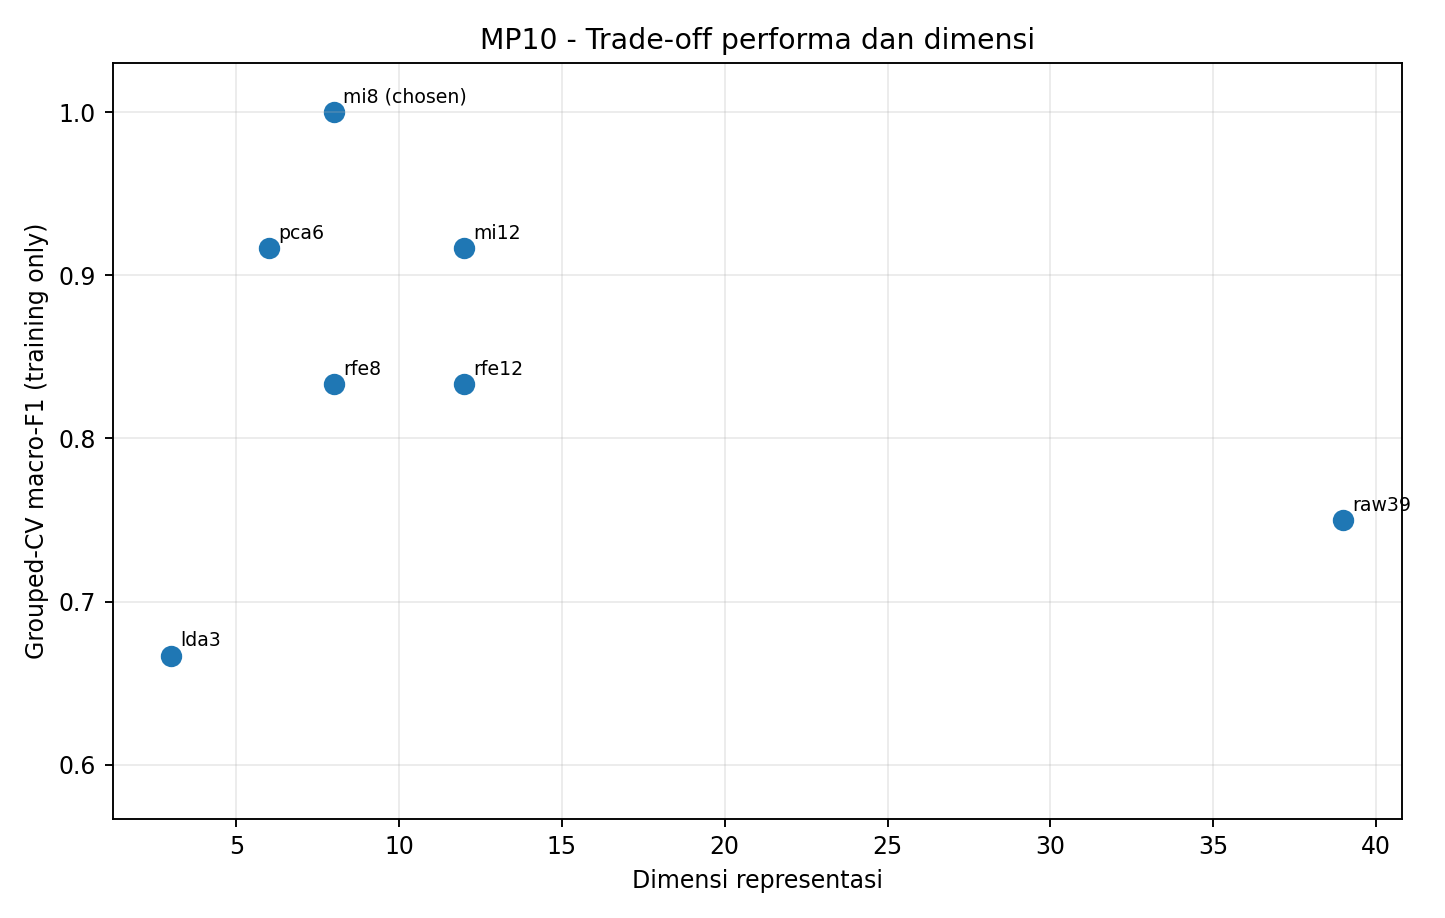

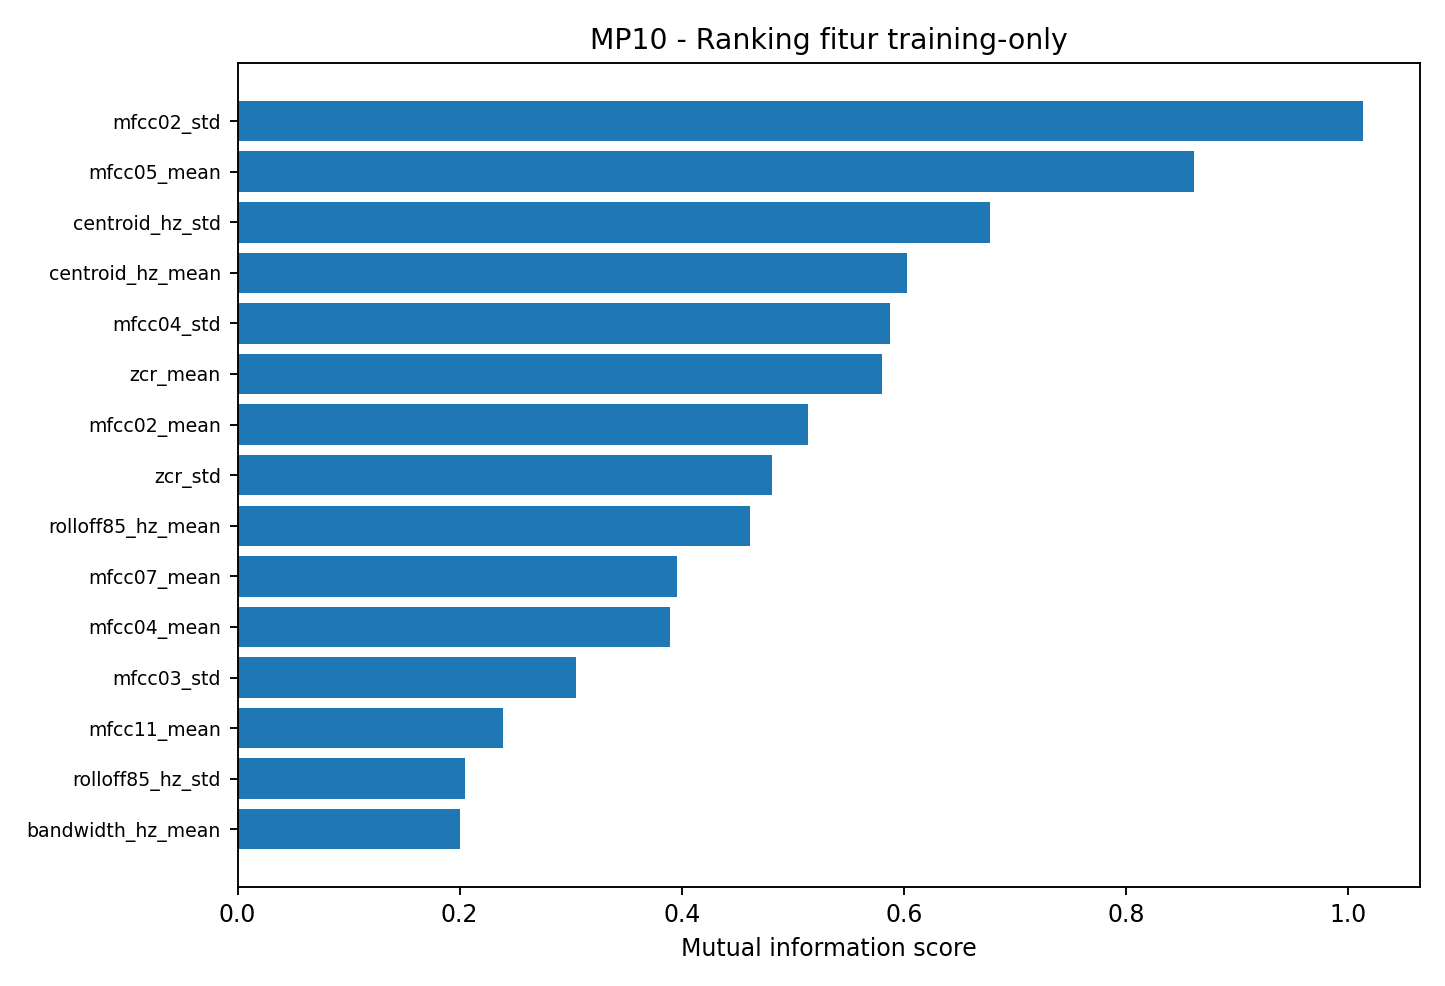

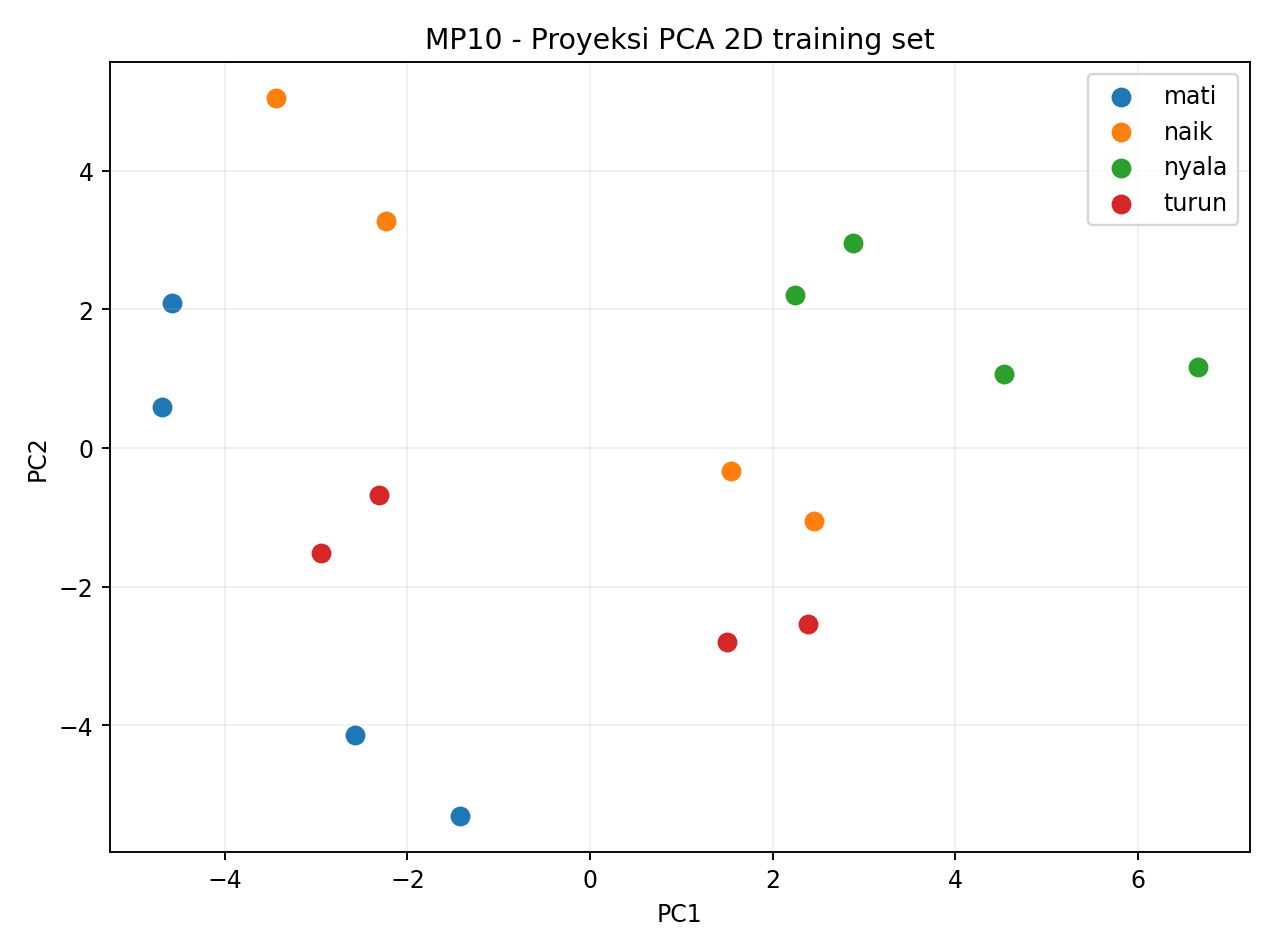

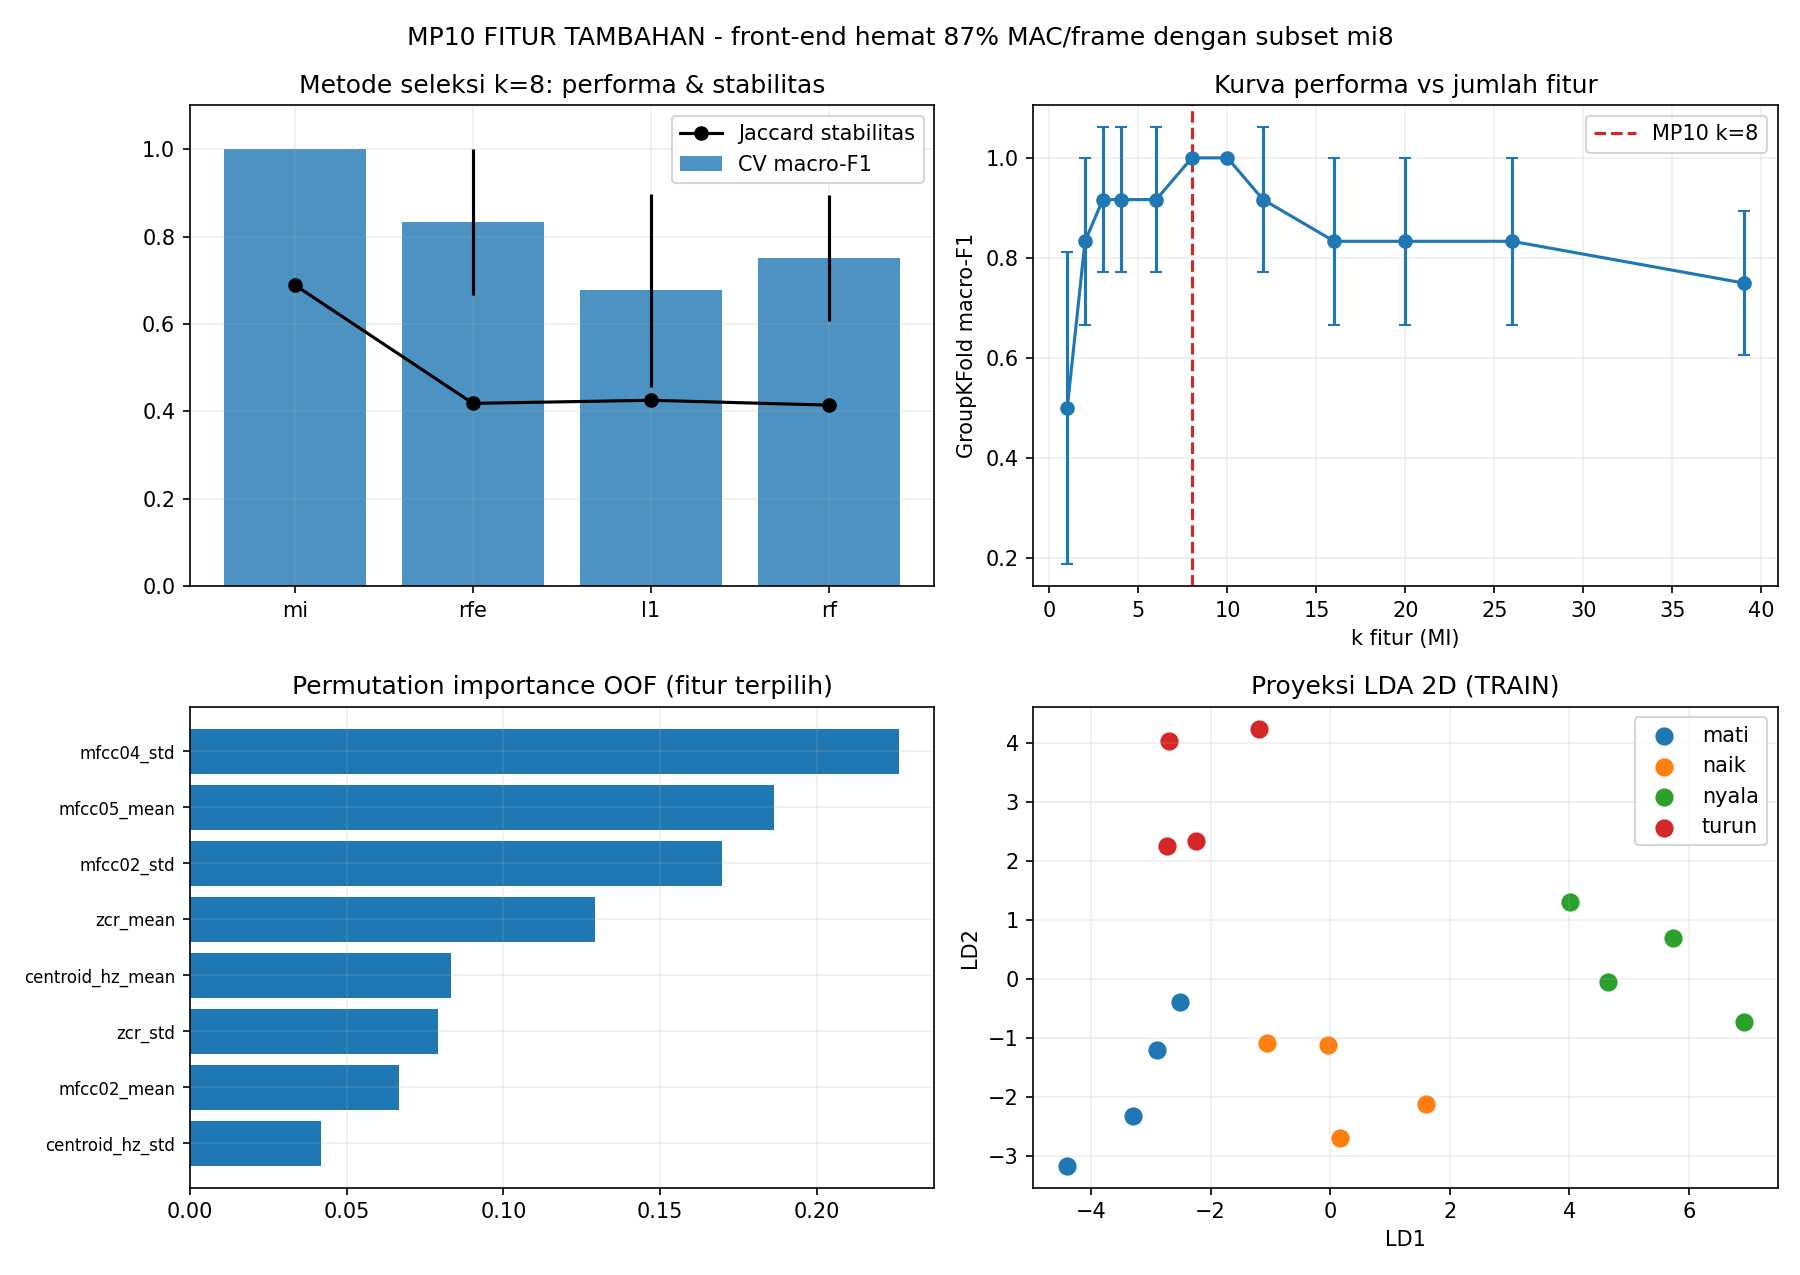

In [17]:
if "__file__" not in globals():
    from IPython.display import Image, display
    for p in ['mp10_representation_tradeoff.png', 'mp10_feature_ranking.png', 'mp10_pca_projection.png', 'mp10_extension_selection_analysis.png']:
        display(Image(filename=str(OUT_FIG/p), width=760))